# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [22]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
import math
import spacy
import numpy as np


## Utils

In [23]:
def displayMetriquesAndGraph(test, prediction) :
    mse = mean_squared_error(test,prediction)

    print(f"Mse: {mse}")
    print(f"RMSE: {math.sqrt(mse)}")
    print(f"R2 Score: {r2_score(test,prediction)}")
    plt.scatter(test, prediction, color='blue', alpha=0.1)

    plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

    plt.title('Prédictions vs Réalité')
    plt.xlabel('Vraies Notes')
    plt.ylabel('Notes Prédites')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)

## 1. Régression linéaire

In [24]:
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)


In [25]:
x_train = x_train.dropna(subset=['text_']).copy()
y_train = y_train.loc[x_train.index].copy()

x_test = x_test.dropna(subset=['text_']).copy()
y_test = y_test.loc[x_test.index].copy()

x_train['text_'] = x_train['text_'].astype(str)
x_test['text_'] = x_test['text_'].astype(str)

nlp = spacy.load("en_core_web_sm") # Charger le package en_core_web_sm

def cleanData(texts):
    processed_texts = []
    for doc in nlp.pipe(texts):
        try:
            # On extrait la version lemmatisé
            tokens = [
                token.lemma_.lower() for token in doc
                if not token.is_stop and not token.is_punct  # Enlever les mots vides (that, is, the...) et les signes de ponctuations
                and token.pos_ in ["ADJ","ADV","VERB","NOUN"] # Garder les mots identifés comme Adverbes, adverbes, verbe, nom
            ]
            processed_texts.append(" ".join(tokens))
        except Exception as e :
            print(f"Erreur sur la phrase : {e}")
    return processed_texts
    
x_train['text_'] = cleanData(x_train['text_'])
x_test['text_'] = cleanData(x_test['text_'])

# Supprimer les lignes vides
x_train['text_'] = x_train['text_'].replace("", np.nan) 
x_test['text_'] = x_test['text_'].replace("", np.nan)

x_train = x_train.dropna(subset=['text_']).copy()
x_test = x_test.dropna(subset=['text_']).copy()

# Mettre à jour les df de résultats
y_train = y_train.loc[x_train.index]
y_test = y_test.loc[x_test.index]

### 1.1 Régression avec le texte - Linear Regression

Processeur : drop
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 100}
Meilleure RMSE : 1.527
Mse: 1.5032473520300924
RMSE: 1.2260698805655788
R2 Score: 0.16280212054473053


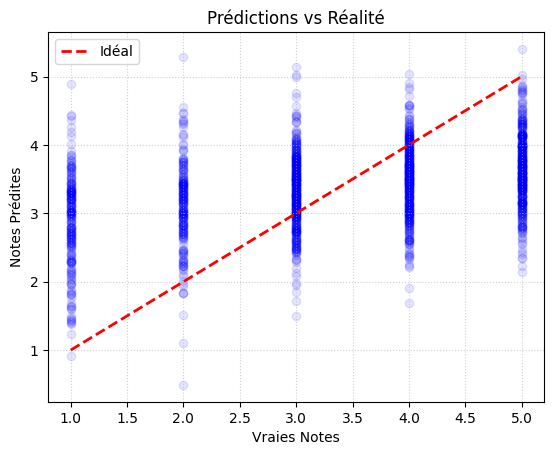

In [26]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=100, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search_linear_regression.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")


prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction_linear_regression)


### Régression sur une catégorie - Pet_Supplies_5 LinearRegression

Processeur : drop
Fitting 5 folds for each of 25 candidates, totalling 125 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 50, 'preprocessor__review__min_df': 100}
Meilleure RMSE : 1.496
Mse: 1.7086945467561971
RMSE: 1.3071704352364297
R2 Score: 0.0015911699491565345


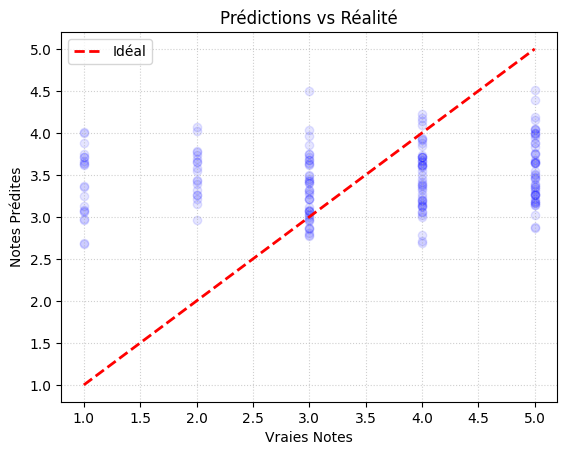

In [27]:
# Isolation de la colonne petSupply 5
pet_supplies_x_train = x_train[x_train['category'] == 'Books_5']
pet_supplies_x_test = x_test[x_test['category'] == 'Books_5']
pet_supplies_y_train = y_train.loc[pet_supplies_x_train.index]
pet_supplies_y_test = y_test.loc[pet_supplies_x_test.index]

# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=100, # Garder les X termes plus importants
            min_df=50, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_')
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [50,100,500,1000,2000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search_linear_regression.fit(pet_supplies_x_train, pet_supplies_y_train)

print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")


prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(pet_supplies_x_test)

displayMetriquesAndGraph(pet_supplies_y_test,prediction_linear_regression)

### 1.3 Régression avec le texte - Ridge

Processeur : drop
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 5000, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 1.487
Mse: 1.4687262021987415
RMSE: 1.2119101460911785
R2 Score: 0.1820278543510363


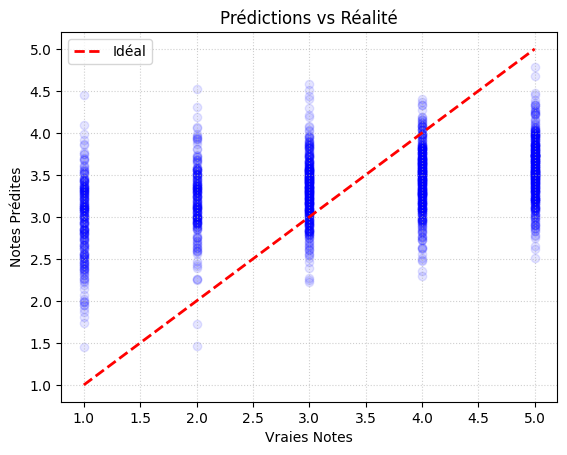

In [31]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge(alpha=10))
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction)

### 1.3 Texte + catégorie - Ridge

Processeur : drop
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 1.477
Mse: 1.445003681200187
RMSE: 1.2020830591935763
R2 Score: 0.19523954851999792


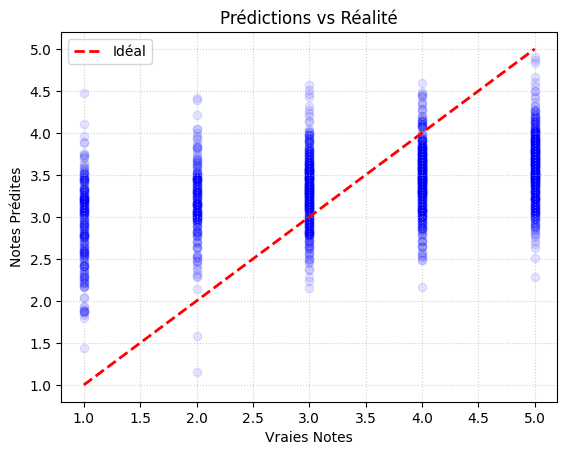

In [32]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
        ('category',OneHotEncoder(),['label'])
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge(alpha=10))
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction)

### 1.4 Lasso

Processeur : drop
Fitting 5 folds for each of 105 candidates, totalling 525 fits
Meilleurs paramètres : {'classifier__alpha': 0.0001, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 100}
Meilleure RMSE : 1.513
Mse: 1.489736991275438
RMSE: 1.220547824247554
R2 Score: 0.17032639481615863


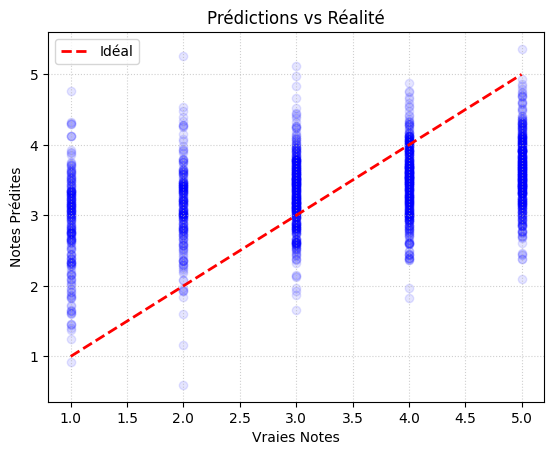

In [30]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Lasso(alpha=0.0001))
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
    'classifier__alpha': [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction)


## 2. Synthèse des expérimentations et des résultats obtenus

### Protocole d'expérimentations

Pour chacune des expérimentations la fonction `GridSearchCV` est utilisé afin de trouver les meilleurs paramètres, elle à pour instruction de se baser sur la `neg_mean_squared_error`, on utilise `neg` car par défaut la fonction cherche à obtenir la valeur la plus haute alors qu'ici on cherche la valeur la plus basse, on utilise la validation croisée avec `5` itérations pour obtenir une moyenne avec du sens.

Une fois les meilleurs paramètres trouvés on réalise l'entrainement et les prédictions sur ces derniers, enfin on affiche les métriques et les graphiques correspondant.

### Tableaux des paramètres

| Nom                                      | max_features | min_df | ngram_ranges | alpha  | stop_words | use_idf |
| ---------------------------------------- | ------------ | ------ | ------------ | ------ | ---------- | ------- |
| Reg text - LinearRegression              | 2000         | 100    | 1,2          | /      | english    | True    |
| Reg catégorie - PetSupplies5 - LinearReg | 100          | 50     | 1,2          | /      | english    | True    |
| Reg texte - Ridge                        | 2000         | 10     | 1,2          | 10     | english    | True    |
| Reg texte + categorie - Ridge            | 2000         | 10     | 1,2          | 10     | english    | True    |
| Reg texte - Lasso                        | 2000         | 10     | 1,2          | 0.0001 | english    | True    |

### Tableaux des résultats

| Nom                                      | MSE  | RMSE | R2    |
| ---------------------------------------- | ---- | ---- | ----- |
| Reg text - LinearRegression              | 1.5  | 1.22 | 0.16  |
| Reg catégorie - PetSupplies5 - LinearReg | 1.7  | 1.3  | 0.001 |
| Reg texte - Ridge                        | 1.46 | 1.21 | 0.18  |
| Reg texte + catégorie - Ridge            | 1.44 | 1.2  | 0.2   |
| Reg texte - Lasso                        | 1.49 | 1.22 | 0.17  |
